## Integral Image

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap

# Volta Redonda-inspired drafting palette
PAPER, ALLOY, INK, VOLTA, GRAPHITE = "#F7F6F0", "#EAE7DC", "#111214", "#FFD100", "#5C626E"

img = np.array([[1, 2, 3, 4],
                [5, 6, 7, 8],
                [9, 1, 2, 3],
                [4, 5, 6, 7]], dtype=np.int64)
H, W = img.shape
S = np.zeros((H + 1, W + 1), dtype=np.int64)
frames = []

# Build the integral image and preserve each intermediate state.
for y in range(H):
    row_running = 0
    for x in range(W):
        row_running += int(img[y, x])
        S[y + 1, x + 1] = S[y, x + 1] + row_running
        frames.append((y, x, S.copy()[1:, 1:], row_running, S[y, x + 1], S[y + 1, x + 1]))

fig = plt.figure(figsize=(8, 8), facecolor=PAPER)
gs = fig.add_gridspec(2, 2, height_ratios=[0.18, 0.72],
                      left=0.09, right=0.93, top=0.91, bottom=0.19,
                      wspace=0.28, hspace=0.12)
title_ax = fig.add_subplot(gs[0, :])
title_ax.axis("off")
title_ax.text(0, 0.78, "INTEGRAL IMAGE / ACCUMULATED AREA",
              fontsize=14, fontweight="bold", color=INK)
title_ax.text(0, 0.28, "Each output cell sums the rectangle from the origin to that coordinate.",
              fontsize=8.5, color=GRAPHITE)

ax_in, ax_out = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
cmap = ListedColormap([ALLOY, VOLTA])
in_im = ax_in.imshow(np.zeros((H, W)), cmap=cmap, vmin=0, vmax=1, interpolation="none")
out_im = ax_out.imshow(np.zeros((H, W)), cmap=cmap, vmin=0, vmax=1, interpolation="none")

for ax, rows, cols, title in [
    (ax_in, H, W, "01 / SOURCE IMAGE"),
    (ax_out, H, W, "02 / INTEGRAL IMAGE S")
]:
    ax.set_title(title, loc="left", fontsize=9, fontweight="bold", color=INK, pad=12)
    ax.set_xticks(range(cols)); ax.set_yticks(range(rows))
    ax.set_xticks(np.arange(-.5, cols, 1), minor=True)
    ax.set_yticks(np.arange(-.5, rows, 1), minor=True)
    ax.grid(which="minor", color=GRAPHITE, linewidth=0.8)
    ax.tick_params(which="both", length=0, labelsize=8, colors=GRAPHITE)
    for spine in ax.spines.values():
        spine.set_visible(False)

in_texts = [[ax_in.text(x, y, str(img[y, x]), ha="center", va="center",
                        color=INK, fontsize=13, fontweight="bold")
             for x in range(W)] for y in range(H)]
out_texts = [[ax_out.text(x, y, "0", ha="center", va="center",
                          color=INK, fontsize=10, fontweight="bold")
              for x in range(W)] for y in range(H)]

ax_in.set_xlabel("column x", fontsize=8, color=GRAPHITE)
ax_out.set_xlabel("column j", fontsize=8, color=GRAPHITE)
ax_in.set_ylabel("row y", fontsize=8, color=GRAPHITE)
ax_out.set_ylabel("row i", fontsize=8, color=GRAPHITE)

status = fig.text(0.09, 0.115, "", color=INK, fontsize=10, fontweight="bold")
equation = fig.text(0.09, 0.075, "", color=GRAPHITE, fontsize=8.5,
                    family="DejaVu Sans Mono")
fig.text(0.93, 0.025, "SIGNAL-PROCESSING NOTE / 01",
         ha="right", color=GRAPHITE, fontsize=7)

def update(k):
    y, x, s_now, row_sum, above, value = frames[k]
    # Yellow marks every source pixel included in this integral-image value.
    source_mask = np.zeros((H, W), dtype=int)
    source_mask[:y+1, :x+1] = 1
    in_im.set_data(source_mask)

    # Highlight the corresponding destination cell in the padded integral image.
    target_mask = np.zeros((H, W), dtype=int)
    target_mask[y, x] = 1
    out_im.set_data(target_mask)

    for i in range(H):
        for j in range(W):
            out_texts[i][j].set_text(str(s_now[i, j]))

    status.set_text(f"TARGET S[{y+1}, {x+1}] = {value}")
    equation.set_text(f"YELLOW AREA SUM = {value}   |   row_running {row_sum} + above {above}")
    return [in_im, out_im, status, equation] + [t for row in out_texts for t in row]

ani = FuncAnimation(fig, update, frames=len(frames), interval=850, blit=False, repeat=True)
ani.save("integral_image_area.gif", writer=PillowWriter(fps=1.2), dpi=110)
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap

# ---------------------------------------------------------
# RECTANGLE SUM / FOUR-CORNER INCLUSION-EXCLUSION
# ---------------------------------------------------------
PAPER, ALLOY, INK, VOLTA, GRAPHITE = "#F7F6F0", "#EAE7DC", "#111214", "#FFD100", "#5C626E"


# Rectangle coordinates in the SOURCE image (inclusive)
y1, x1 = 1, 1
y2, x2 = 3, 2

img = np.array([[1, 2, 3, 4],
                [5, 6, 7, 8],
                [9, 1, 2, 3],
                [4, 5, 6, 7]], dtype=np.int64)
H, W = img.shape

# Four corners in the PADDED integral image
corners = [
    ("A", x2 + 1, y2 + 1, +1),
    ("B", x2 + 1, y1,     -1),
    ("C", x1,     y2 + 1, -1),
    ("D", x1,     y1,     +1),
]

values = [int(S[cy, cx]) for _, cx, cy, _ in corners]
result = sum(sign * value for (_, _, _, sign), value
             in zip(corners, values))

# Figure
fig2 = plt.figure(figsize=(10, 7), facecolor=PAPER)
gs2 = fig2.add_gridspec(
    2, 2,
    height_ratios=[0.20, 0.72],
    left=0.09, right=0.93,
    top=0.90, bottom=0.22,
    wspace=0.32, hspace=0.20
)

title_ax = fig2.add_subplot(gs2[0, :])
title_ax.axis("off")
title_ax.text(
    0, 0.78, "RECTANGLE SUM / FOUR-CORNER TRICK",
    fontsize=14, fontweight="bold", color=INK
)
title_ax.text(
    0, 0.25,
    "Any rectangular area can be recovered using four integral-image values.",
    fontsize=8.5, color=GRAPHITE
)

ax_src = fig2.add_subplot(gs2[1, 0])
ax_int = fig2.add_subplot(gs2[1, 1])

# Source image
ax_src.imshow(
    np.zeros_like(img), cmap=ListedColormap([ALLOY, VOLTA]),
    vmin=0, vmax=1, interpolation="none"
)
ax_src.set_title(
    "01 / QUERY RECTANGLE",
    loc="left", fontsize=9, fontweight="bold",
    color=INK, pad=12
)

# Highlight requested rectangle
rect = Rectangle(
    (x1 - 0.5, y1 - 0.5),
    x2 - x1 + 1, y2 - y1 + 1,
    linewidth=2, edgecolor=VOLTA,
    facecolor=VOLTA, alpha=0.35
)
ax_src.add_patch(rect)

for y in range(H):
    for x in range(W):
        ax_src.text(
            x, y, str(img[y, x]),
            ha="center", va="center",
            color=INK, fontsize=12, fontweight="bold"
        )

ax_src.set_xticks(range(W))
ax_src.set_yticks(range(H))
ax_src.set_xticks(np.arange(-.5, W, 1), minor=True)
ax_src.set_yticks(np.arange(-.5, H, 1), minor=True)
ax_src.grid(which="minor", color=GRAPHITE, linewidth=0.8)
ax_src.tick_params(which="both", length=0, labelsize=8)

# Padded integral image
ax_int.imshow(
    np.zeros_like(S), cmap=ListedColormap([ALLOY, VOLTA]),
    vmin=0, vmax=1, interpolation="none"
)
ax_int.set_title(
    "02 / FOUR CORNER VALUES",
    loc="left", fontsize=9, fontweight="bold",
    color=INK, pad=12
)

for y in range(H + 1):
    for x in range(W + 1):
        ax_int.text(
            x, y, str(S[y, x]),
            ha="center", va="center",
            color=INK, fontsize=9, fontweight="bold"
        )

ax_int.set_xticks(range(W + 1))
ax_int.set_yticks(range(H + 1))
ax_int.set_xticks(np.arange(-.5, W + 1, 1), minor=True)
ax_int.set_yticks(np.arange(-.5, H + 1, 1), minor=True)
ax_int.grid(which="minor", color=GRAPHITE, linewidth=0.8)
ax_int.tick_params(which="both", length=0, labelsize=8)

# Four animated dots
dot_artists = []
label_artists = []

for name, cx, cy, sign in corners:
    color = VOLTA if sign == 1 else GRAPHITE

    dot, = ax_int.plot(
        [], [], marker="o", markersize=13,
        markerfacecolor=color, markeredgecolor=INK,
        markeredgewidth=1.2, linestyle="none",
        zorder=5
    )
    dot_artists.append(dot)

    label = ax_int.text(
        cx + 0.15, cy - 0.35,
        f"{name} {'+' if sign > 0 else '-'} {S[cy,cx]}",
        fontsize=8, fontweight="bold",
        color=INK, ha="left", va="bottom",
        visible=False, zorder=6
    )
    label_artists.append(label)

# Status and equation
status2 = fig2.text(
    0.09, 0.145, "",
    fontsize=10, fontweight="bold", color=INK
)
equation2 = fig2.text(
    0.09, 0.095, "",
    fontsize=10, color=GRAPHITE,
    family="DejaVu Sans Mono"
)

fig2.text(
    0.93, 0.025, "SIGNAL-PROCESSING NOTE / 02",
    ha="right", color=GRAPHITE, fontsize=7
)

# Progressive animation:
# 0 = rectangle only
# 1 = A
# 2 = A, B
# 3 = A, B, C
# 4 = A, B, C, D
# 5 = final equation

def update_rectangle(k):

    # Show source rectangle
    source_mask = np.zeros((H, W), dtype=int)
    source_mask[y1:y2+1, x1:x2+1] = 1

    ax_src.images[0].set_data(source_mask)

    # Activate dots progressively
    active = min(k, 4)

    for i, (name, cx, cy, sign) in enumerate(corners):
        if i < active:
            dot_artists[i].set_data([cx], [cy])
            label_artists[i].set_visible(True)
        else:
            dot_artists[i].set_data([], [])
            label_artists[i].set_visible(False)

    if k == 0:
        status2.set_text(
            f"QUERY: rows {y1}–{y2} / columns {x1}–{x2}"
        )
        equation2.set_text(
            "Select the rectangular region to sum."
        )

    elif k < 5:
        name, cx, cy, sign = corners[k-1]
        value = S[cy, cx]

        status2.set_text(
            f"CORNER {name}: {'ADD' if sign > 0 else 'SUBTRACT'} {value}"
        )
        equation2.set_text(
            f"Accumulating four boundary values..."
        )

    else:
        status2.set_text(
            f"FINAL RECTANGLE SUM = {result}"
        )
        equation2.set_text(
            f"{values[0]} - {values[1]} - {values[2]} + {values[3]} = {result}"
        )

    return (
        [ax_src.images[0]]
        + dot_artists + label_artists
        + [status2, equation2]
    )

ani2 = FuncAnimation(
    fig2, update_rectangle,
    frames=6, interval=1500,
    blit=False, repeat=True
)

ani2.save(
    "rectangle_sum_four_corners.gif",
    writer=PillowWriter(fps=0.8),
    dpi=110
)

plt.show()


## Eye Strip detection

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import math

In [2]:
def integral_image(img: np.ndarray) -> np.ndarray:
    H, W = img.shape
    S = np.zeros((H + 1, W + 1), dtype=np.int64)
    for y in range(H):
        row_running = 0
        for x in range(W):
            row_running += int(img[y, x])
            S[y + 1, x + 1] = S[y, x + 1] + row_running   # S[i,j] = S[i-1,j] + rowsum
    return S

def rect_sum(S: np.ndarray, y0: int, x0: int, y1: int, x1: int) -> int:
    """Four lookups, independent of rectangle size."""
    return S[y1, x1] - S[y0, x1] - S[y1, x0] + S[y0, x0]

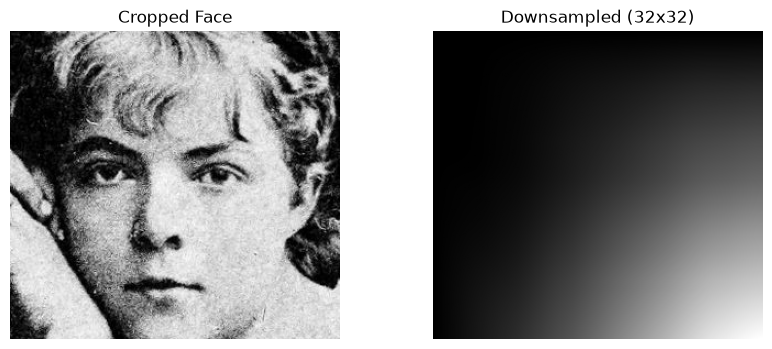

In [4]:
img_full = cv2.imread("../../../resources/marie_bashkirtseff.jpg", cv2.IMREAD_GRAYSCALE)
y0, y1 = 180, 460
x0, x1 = 400, 700
img = img_full[y0:y1, x0:x1]
H, W = img.shape
img_integral = integral_image(img)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img, cmap='gray'); plt.title("Cropped Face"); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(img_integral, cmap='gray'); plt.title("Downsampled (32x32)"); plt.axis('off')
plt.show()

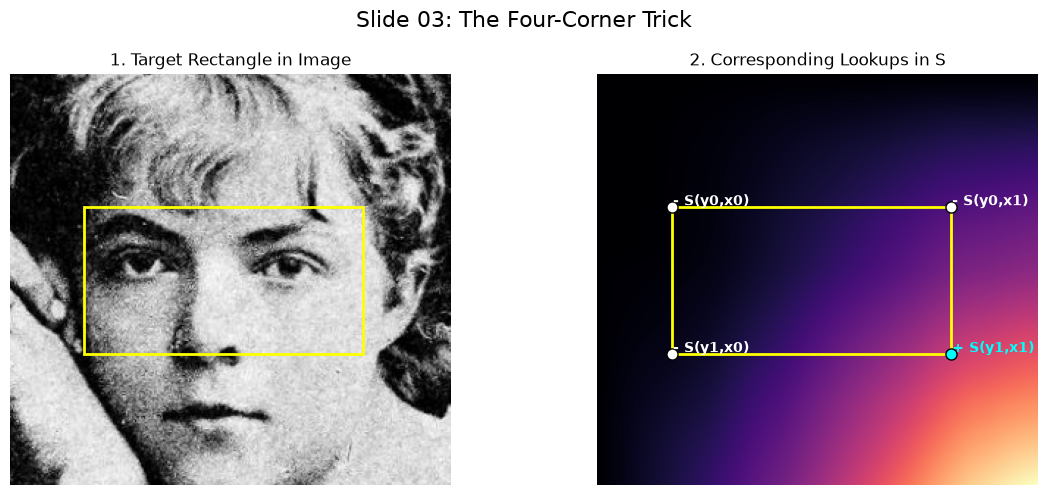

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Slide 03: The Four-Corner Trick", fontsize=16)

# Left: The original image with a target rectangle
ry0, rx0, ry1, rx1 = 90, 50, 190, 240
axes[0].imshow(img, cmap='gray')
axes[0].add_patch(Rectangle((rx0, ry0), rx1-rx0, ry1-ry0, fill=False, edgecolor='yellow', linewidth=2))
axes[0].set_title("1. Target Rectangle in Image")
axes[0].axis('off')

# Right: The integral image
axes[1].imshow(img_integral[1:, 1:], cmap='magma')
axes[1].set_title("2. Corresponding Lookups in S")

# Plot the 4 corners
corners = [(ry0, rx0), (ry1, rx0), (ry0, rx1), (ry1, rx1)]
labels = ["- S(y0,x0)", "- S(y1,x0)", "- S(y0,x1)", "+ S(y1,x1)"]
colors = ["white", "white", "white", "cyan"]
axes[1].add_patch(Rectangle((rx0, ry0), rx1-rx0, ry1-ry0, fill=False, edgecolor='yellow', linewidth=2))
for (cy, cx), label, color in zip(corners, labels, colors):
    axes[1].plot(cx, cy, 'o', color=color, markersize=8, markeredgecolor='black')
    axes[1].text(cx+1, cy-1, label, color=color, fontsize=10, fontweight='bold')

axes[1].axis('off')
plt.tight_layout()
plt.show()

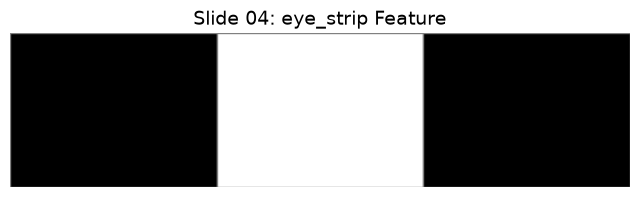

In [7]:
S2 = np.zeros((H + 1, W + 1), dtype=np.int64)
S2[1:, 1:] = img.astype(np.int64) ** 2
np.cumsum(S2, axis=0, out=S2)
np.cumsum(S2, axis=1, out=S2)

S_full = integral_image(img)

# 2. The template
TEMPLATE_EYE_STRIP = [
    (-1, (0, 0, 1, 1)), # Dark left
    (+2, (0, 1, 1, 2)), # Bright center
    (-1, (0, 2, 1, 3))  # Dark right
]

def eval_template(y, x, cell_h, cell_w, template):
    total, area = 0.0, 0.0
    min_y, max_y = y, y
    min_x, max_x = x, x

    for w, (ry0, rx0, ry1, rx1) in template:
        ty0, ty1 = y + ry0 * cell_h, y + ry1 * cell_h
        tx0, tx1 = x + rx0 * cell_w, x + rx1 * cell_w
        total += w * rect_sum(S_full, ty0, tx0, ty1, tx1)
        area  += abs(w) * (ry1 - ry0) * (rx1 - rx0) * cell_h * cell_w
        min_y, max_y = min(min_y, ty0), max(max_y, ty1)
        min_x, max_x = min(min_x, tx0), max(max_x, tx1)

    # Raw response (divided by area to normalize for scale)
    raw = total / area
    
    # Local variance normalization
    b_area = (max_y - min_y) * (max_x - min_x)
    s = rect_sum(S_full, min_y, min_x, max_y, max_x)
    s2 = rect_sum(S2, min_y, min_x, max_y, max_x)
    mean = s / b_area
    var = max(0.0, s2 / b_area - mean**2)
    
    return raw / (np.sqrt(var) + 1e-5)

# --- VISUALIZATION FOR SLIDE 4 (Feature Diagram) ---
fig, ax = plt.subplots(figsize=(8, 2))
for w, (ry0, rx0, ry1, rx1) in TEMPLATE_EYE_STRIP:
    ax.add_patch(Rectangle((rx0, ry0), rx1-rx0, ry1-ry0, facecolor="white" if w>0 else "black", edgecolor="gray"))
ax.set_xlim(0, 3); ax.set_ylim(1, 0)
ax.axis('off'); ax.set_title("Slide 04: eye_strip Feature", fontsize=14)
plt.show()

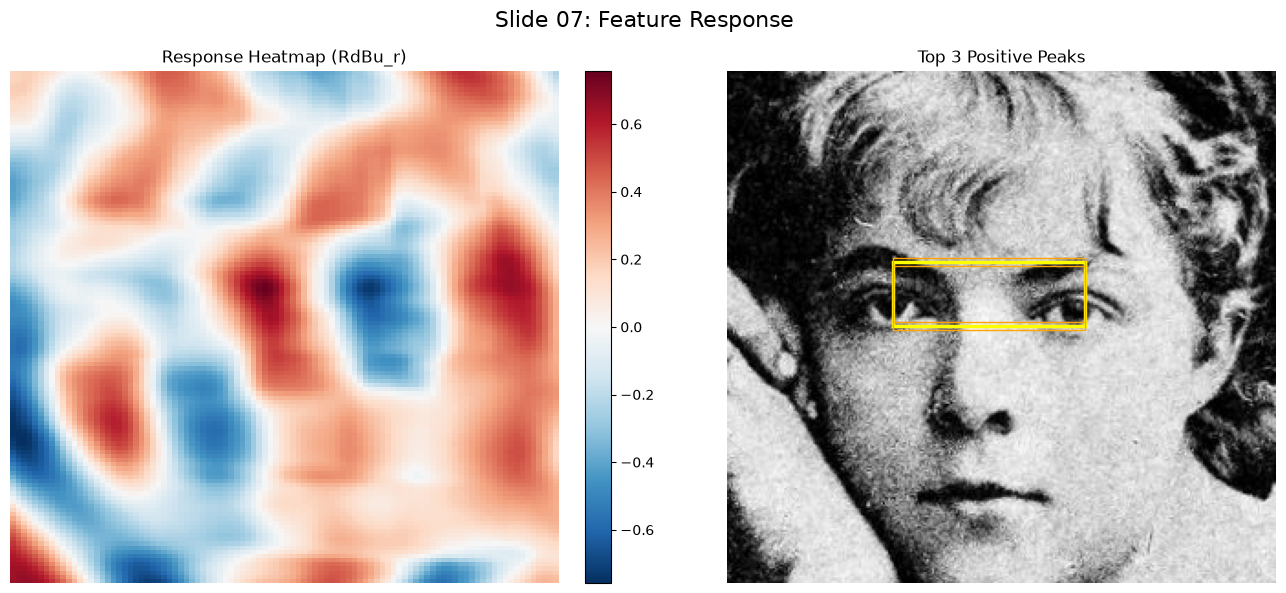

In [9]:
# %%
CELL = 35
STEP = 2

fh = 1 * CELL
fw = 3 * CELL
ys = np.arange(0, H - fh + 1, STEP)
xs = np.arange(0, W - fw + 1, STEP)
R = np.zeros((len(ys), len(xs)))

for i, y in enumerate(ys):
    for j, x in enumerate(xs):
        R[i, j] = eval_template(y, x, CELL, CELL, TEMPLATE_EYE_STRIP)

# --- VISUALIZATION FOR SLIDE 7 (Response Map) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Slide 07: Feature Response", fontsize=16)

# Heatmap
vmax = np.abs(R).max()
im = axes[0].imshow(R, cmap="RdBu_r", vmin=-vmax, vmax=vmax, extent=[0, W, H, 0])
axes[0].set_title("Response Heatmap (RdBu_r)")
axes[0].axis("off")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Top Peaks
axes[1].imshow(img, cmap="gray")
top_indices = np.argsort(R.ravel())[-3:][::-1]
for k, idx in enumerate(top_indices):
    i, j = np.unravel_index(idx, R.shape)
    color = 'yellow' if k == 0 else 'orange'
    lw = 2.5 if k == 0 else 1.0
    axes[1].add_patch(Rectangle((xs[j], ys[i]), fw, fh, fill=False, edgecolor=color, linewidth=lw))
axes[1].set_title("Top 3 Positive Peaks")
axes[1].axis("off")

plt.tight_layout()
plt.show()

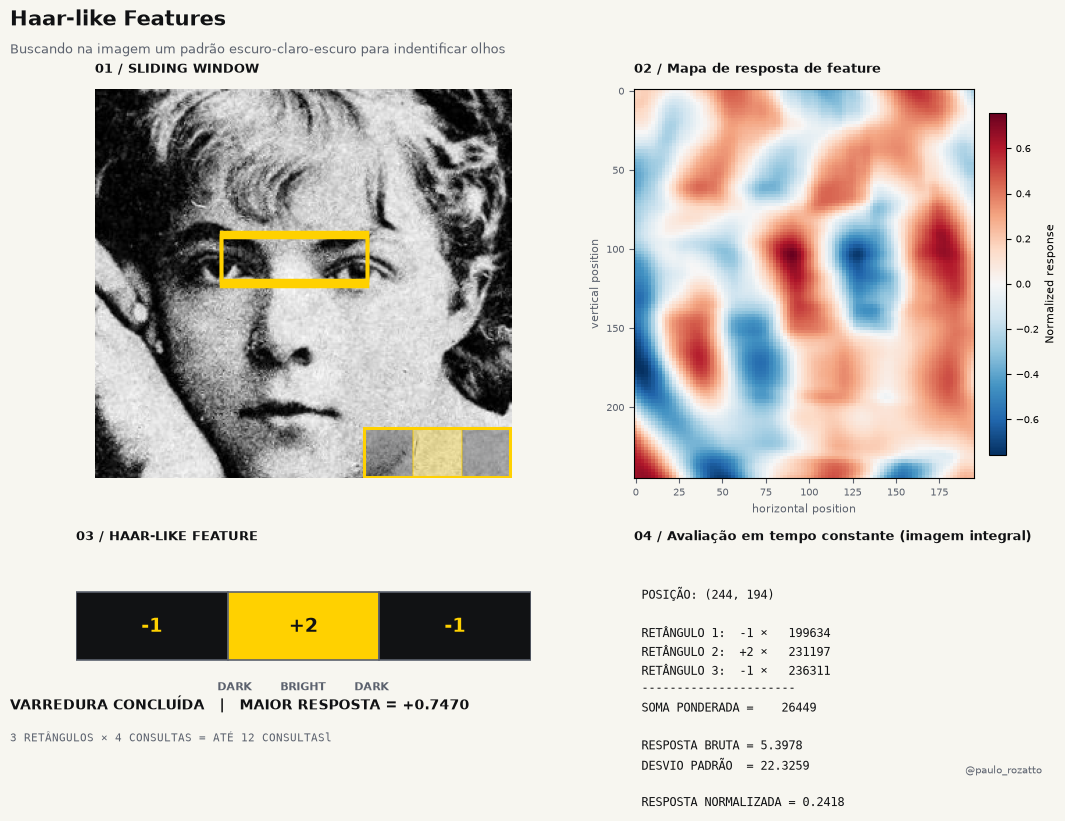

In [15]:

# %%
# SLIDE 05 / APPLICATION: SCANNING FOR AN EYE STRIP
# Requires: img, S_full, S2, R, ys, xs, CELL, STEP,
#           TEMPLATE_EYE_STRIP, eval_template, rect_sum

from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize

# ---------------------------------------------------------
# VOLTA REDONDA DRAFTING PALETTE
# ---------------------------------------------------------
PAPER = "#F7F6F0"
ALLOY = "#EAE7DC"
INK = "#111214"
VOLTA = "#FFD100"
GRAPHITE = "#5C626E"

# ---------------------------------------------------------
# REFERENCE GEOMETRY
# ---------------------------------------------------------
fh = CELL
fw = 3 * CELL

# Scan order: left to right, top to bottom
coordinates = [(i, j) for i in range(len(ys))
               for j in range(len(xs))]

# Limit the animation to a manageable number of frames.
frame_ids = np.unique(
    np.linspace(0, len(coordinates)-1,
                min(110, len(coordinates))).astype(int)
)

# ---------------------------------------------------------
# CALCULATE THE ACTUAL FOUR-CORNER CONTRIBUTIONS
# ---------------------------------------------------------
def explain_evaluation(y, x):

    contributions = []
    cell_sums = []

    for weight, (ry0, rx0, ry1, rx1) in TEMPLATE_EYE_STRIP:

        ty0 = y + ry0 * CELL
        ty1 = y + ry1 * CELL
        tx0 = x + rx0 * CELL
        tx1 = x + rx1 * CELL

        value = rect_sum(S_full, ty0, tx0, ty1, tx1)

        cell_sums.append(value)
        contributions.append(weight * value)

    total = sum(contributions)

    # Normalize by the sum of absolute weighted areas
    area = sum(
        abs(weight) * (ry1-ry0) * (rx1-rx0) * CELL**2
        for weight, (ry0, rx0, ry1, rx1)
        in TEMPLATE_EYE_STRIP
    )

    raw = total / area

    # Local variance in the entire feature bounding box
    mean = rect_sum(S_full, y, x, y+fh, x+fw) / (fh*fw)

    mean2 = rect_sum(S2, y, x, y+fh, x+fw) / (fh*fw)

    variance = max(0.0, mean2 - mean**2)
    std = np.sqrt(variance)

    normalized = raw / (std + 1e-5)

    return cell_sums, contributions, raw, std, normalized


# ---------------------------------------------------------
# FIGURE LAYOUT
# ---------------------------------------------------------
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    facecolor=PAPER,
    gridspec_kw={
        "height_ratios": [0.72, 0.28],
        "width_ratios": [0.55, 0.45],
        "hspace": 0.28,
        "wspace": 0.25
    }
)

ax_img = axes[0, 0]
ax_heat = axes[0, 1]
ax_feature = axes[1, 0]
ax_math = axes[1, 1]

fig.text(
    0.07, 0.96,
    "Haar-like Features",
    fontsize=15, fontweight="bold", color=INK
)

fig.text(
    0.07, 0.925,
    "Buscando na imagem um padrão escuro-claro-escuro para indentificar olhos",
    fontsize=9, color=GRAPHITE
)

# ---------------------------------------------------------
# 1. ORIGINAL IMAGE + MOVING WINDOW
# ---------------------------------------------------------
ax_img.imshow(img, cmap="gray")
ax_img.set_title(
    "01 / SLIDING WINDOW",
    loc="left", fontsize=9, fontweight="bold",
    color=INK, pad=12
)
ax_img.axis("off")

# Main detection window
window = Rectangle(
    (0, 0), fw, fh,
    fill=False, edgecolor=VOLTA,
    linewidth=2.2, zorder=5
)
ax_img.add_patch(window)

# Three feature regions
feature_colors = [INK, VOLTA, INK]
feature_patches = []

for k, (weight, (ry0, rx0, ry1, rx1)) in enumerate(
    TEMPLATE_EYE_STRIP
):
    patch = Rectangle(
        (0, 0),
        (rx1-rx0)*CELL,
        (ry1-ry0)*CELL,
        facecolor=feature_colors[k],
        edgecolor=VOLTA,
        linewidth=1.1,
        alpha=0.30,
        zorder=4
    )
    ax_img.add_patch(patch)
    feature_patches.append(patch)

# ---------------------------------------------------------
# 2. PROGRESSIVE RESPONSE MAP
# ---------------------------------------------------------
vmax = max(float(np.max(np.abs(R))), 1e-8)

heat_data = np.full(R.shape, np.nan)

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad(alpha=0)

heat = ax_heat.imshow(
    np.ma.masked_invalid(heat_data),
    cmap=cmap,
    vmin=-vmax,
    vmax=vmax,
    interpolation="nearest",
    extent=[
        xs[0]-STEP/2,
        xs[-1]+STEP/2,
        ys[-1]+STEP/2,
        ys[0]-STEP/2
    ],
    aspect="auto"
)

ax_heat.set_title(
    "02 / Mapa de resposta de feature",
    loc="left", fontsize=9, fontweight="bold",
    color=INK, pad=12
)
ax_heat.set_xlabel("horizontal position", fontsize=8, color=GRAPHITE)
ax_heat.set_ylabel("vertical position", fontsize=8, color=GRAPHITE)
ax_heat.tick_params(labelsize=7, colors=GRAPHITE)

cbar = fig.colorbar(
    heat, ax=ax_heat, fraction=0.046, pad=0.04
)
cbar.set_label("Normalized response", fontsize=8)
cbar.ax.tick_params(labelsize=7)

# ---------------------------------------------------------
# 3. FEATURE DIAGRAM
# ---------------------------------------------------------
ax_feature.set_facecolor(ALLOY)
ax_feature.set_title(
    "03 / HAAR-LIKE FEATURE",
    loc="left", fontsize=9, fontweight="bold",
    color=INK, pad=10
)

ax_feature.set_xlim(0, 3)
ax_feature.set_ylim(0, 1)
ax_feature.axis("off")

for k, (weight, _) in enumerate(TEMPLATE_EYE_STRIP):

    ax_feature.add_patch(
        Rectangle(
            (k, 0.30), 1, 0.45,
            facecolor=feature_colors[k],
            edgecolor=GRAPHITE,
            linewidth=1.2
        )
    )

    ax_feature.text(
        k+0.5, 0.52,
        f"{weight:+d}",
        ha="center", va="center",
        color=VOLTA if weight < 0 else INK,
        fontsize=14, fontweight="bold"
    )

ax_feature.text(
    1.5, 0.10,
    "DARK       BRIGHT       DARK",
    ha="center", fontsize=8,
    color=GRAPHITE, fontweight="bold"
)

# ---------------------------------------------------------
# 4. LIVE MATHEMATICAL EVALUATION
# ---------------------------------------------------------
ax_math.axis("off")
ax_math.set_title(
    "04 / Avaliação em tempo constante (imagem integral)",
    loc="left", fontsize=9, fontweight="bold",
    color=INK, pad=10
)

math_text = ax_math.text(
    0.02, 0.80, "",
    transform=ax_math.transAxes,
    fontsize=8.5,
    color=INK,
    family="DejaVu Sans Mono",
    va="top",
    linespacing=1.6
)

# ---------------------------------------------------------
# DETECTION CANDIDATES
# ---------------------------------------------------------
top_indices = np.argsort(R.ravel())[-3:][::-1]

detection_patches = []

for idx in top_indices:
    i, j = np.unravel_index(idx, R.shape)

    p = Rectangle(
        (xs[j], ys[i]), fw, fh,
        fill=False,
        edgecolor=VOLTA,
        linewidth=2.5,
        visible=False,
        zorder=8
    )
    ax_img.add_patch(p)
    detection_patches.append(p)

# ---------------------------------------------------------
# STATUS
# ---------------------------------------------------------
status = fig.text(
    0.07, 0.105, "",
    fontsize=10, fontweight="bold", color=INK
)

footer = fig.text(
    0.07, 0.065,
    "3 RETÂNGULOS × 4 CONSULTAS = ATÉ 12 CONSULTASl",
    fontsize=8, color=GRAPHITE,
    family="DejaVu Sans Mono"
)

fig.text(
    0.93, 0.025,
    "@paulo_rozatto",
    ha="right", fontsize=7, color=GRAPHITE
)

# ---------------------------------------------------------
# ANIMATION
# ---------------------------------------------------------
def update_scan(k):

    idx = frame_ids[k]
    i, j = coordinates[idx]

    y, x = int(ys[i]), int(xs[j])

    # Move the detection window
    window.set_xy((x-0.5, y-0.5))

    # Move the three feature regions
    for patch, (weight, (ry0, rx0, ry1, rx1)) in zip(
        feature_patches, TEMPLATE_EYE_STRIP
    ):
        patch.set_xy((
            x + rx0*CELL - 0.5,
            y + ry0*CELL - 0.5
        ))

    # Progressively reveal the evaluated response map
    heat_data = np.full(R.size, np.nan)
    heat_data[:idx+1] = R.ravel()[:idx+1]

    heat.set_data(
        np.ma.masked_invalid(heat_data.reshape(R.shape))
    )

    # Evaluate the current position
    sums, contributions, raw, std, score = explain_evaluation(y, x)

    # Live mathematical explanation
    math_text.set_text(
    f"POSIÇÃO: ({y}, {x})\n\n"
    f"RETÂNGULO 1:  -1 × {sums[0]:>8}\n"
    f"RETÂNGULO 2:  +2 × {sums[1]:>8}\n"
    f"RETÂNGULO 3:  -1 × {sums[2]:>8}\n"
    f"----------------------\n"
    f"SOMA PONDERADA = {sum(contributions):>8}\n\n"
    f"RESPOSTA BRUTA = {raw:.4f}\n"
    f"DESVIO PADRÃO  = {std:.4f}\n"
    f"\nRESPOSTA NORMALIZADA = {score:.4f}"
)

    status.set_text(
    f"VARREDURA: {idx+1}/{len(coordinates)} POSIÇÕES"
    f"     |     RESPOSTA = {score:+.4f}"
)

    # Show the strongest candidate regions at the end
    if k == len(frame_ids)-1:
        for p in detection_patches:
            p.set_visible(True)

        status.set_text(
            f"VARREDURA CONCLUÍDA   |   MAIOR RESPOSTA = {R.ravel()[top_indices[0]]:+.4f}"
        )

    else:
        for p in detection_patches:
            p.set_visible(False)

    return (
        [window, heat, math_text, status]
        + feature_patches
        + detection_patches
    )


ani_scan = FuncAnimation(
    fig,
    update_scan,
    frames=len(frame_ids),
    interval=180,
    blit=False,
    repeat=False
)

ani_scan.save(
    "eye_strip_detection.gif",
    writer=PillowWriter(fps=8),
    dpi=110
)

plt.show()


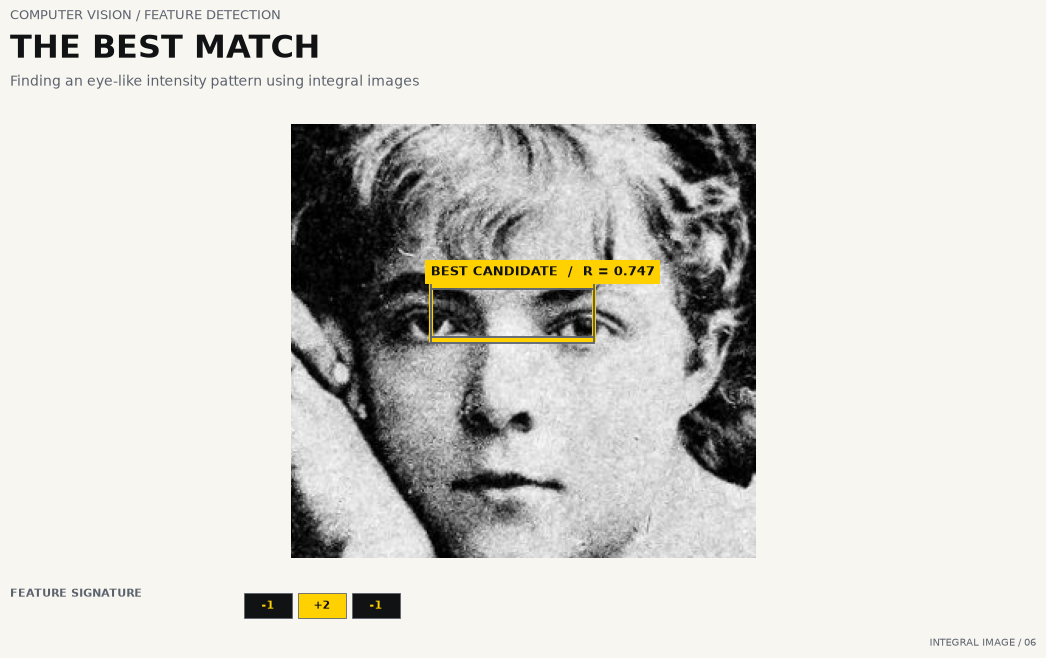

In [11]:

# %%
# SLIDE 06 / FINAL RESULT
# FINAL EYE-STRIP CANDIDATE

fig, ax = plt.subplots(figsize=(12, 7), facecolor=PAPER)

fig.text(
    0.075, 0.93,
    "COMPUTER VISION / FEATURE DETECTION",
    fontsize=9, color=GRAPHITE
)

fig.text(
    0.075, 0.875,
    "THE BEST MATCH",
    fontsize=23, fontweight="bold", color=INK
)

fig.text(
    0.075, 0.835,
    "Finding an eye-like intensity pattern using integral images",
    fontsize=10, color=GRAPHITE
)

ax.imshow(img, cmap="gray")

# Find three strongest positive responses
top_indices = np.argsort(R.ravel())[-3:][::-1]

for rank, idx in enumerate(top_indices):
    i, j = np.unravel_index(idx, R.shape)

    x, y = xs[j], ys[i]
    score = R[i, j]

    color = VOLTA if rank == 0 else GRAPHITE
    linewidth = 3 if rank == 0 else 1.3

    ax.add_patch(
        Rectangle(
            (x, y), fw, fh,
            fill=False,
            edgecolor=color,
            linewidth=linewidth
        )
    )

    if rank == 0:
        ax.text(
            x, y-7,
            f"BEST CANDIDATE  /  R = {score:.3f}",
            color=INK,
            fontsize=9,
            fontweight="bold",
            bbox=dict(
                facecolor=VOLTA,
                edgecolor="none",
                pad=4
            )
        )

ax.axis("off")

# Feature signature
fig.text(
    0.075, 0.105,
    "FEATURE SIGNATURE",
    fontsize=8, color=GRAPHITE, fontweight="bold"
)

# Three small feature cells
for k, (weight, _) in enumerate(TEMPLATE_EYE_STRIP):
    x = 0.27 + k*0.045

    fig.patches.append(
        Rectangle(
            (x, 0.075), 0.04, 0.035,
            transform=fig.transFigure,
            facecolor=INK if weight < 0 else VOLTA,
            edgecolor=GRAPHITE,
            linewidth=0.6
        )
    )

    fig.text(
        x+0.02, 0.092,
        f"{weight:+d}",
        ha="center", va="center",
        fontsize=8,
        color=VOLTA if weight < 0 else INK,
        fontweight="bold"
    )

fig.text(
    0.93, 0.035,
    "INTEGRAL IMAGE / 06",
    ha="right", fontsize=7, color=GRAPHITE
)

plt.subplots_adjust(
    left=0.075, right=0.93,
    top=0.78, bottom=0.16
)

plt.savefig(
    "final_eye_strip_detection.png",
    dpi=180,
    facecolor=PAPER,
    bbox_inches="tight"
)

plt.show()
